In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import smplotlib

sb_const = 5.67e-8 
kb_const = 1.38e-23
bigG_const = 6.6743e-11
mass_hydrogen = 1.007825 * 1.660539068e-27 

def solar_flux(r_au):
    
    return 1366 / r_au**2

def equib_temp(r_au):
    
    f = solar_flux(r_au)

    return (f/(4*sb_const))**(1/4)


def lambda_esc(r_au,m_planet,r_planet):
    
    T = equib_temp(r_au)
    
    return (bigG_const * m_planet * mass_hydrogen)/(kb_const*T*r_planet)

r_varuna = 355e3
mass_varuna = 990 * (4/3 * np.pi * r_varuna**3) #estimate

 #r_au, mass planet, radius planet   
planet_dict = {'Mercury':[[0.3871,0.330e24,2439e3],'k'],
               'Venus':[[0.723,4.86e24,6051e3],'k'],
               'Earth':[[1.00,5.97e24,6371e3],'k'],
               'Mars':[[1.523,0.64e24,3389e3],'k'],
               'Jupiter':[[5.203,1898e24,71492e3],'k'],
               'Saturn':[[9.543,568e24,60268e3],'k'],
               'Uranus':[[19.192,86.8e24,25559e3],'k'],
               'Neptune':[[30.069,102e24,24766e3],'k'],
               'Pluto':[[39.48,1.33e22,1188e3],'b'],
               'Io':[[5.203,893e20,1821e3],'r'],
               'Ganymede':[[5.203,1482e20,2634e3],'r'],
               'Titan':[[9.543,1345e20,2575e3],'r'],
               'Enceladus':[[9.543,0.65e20,250e3],'r'],
               'Ceres':[[2.766,94.3e19,467e3],'g'],
               'Eris':[[67.728,1670e19,1162e3],'b'],
               'Varuna':[[40.8,mass_varuna,r_varuna],'b']}

Mercury 2.4458097686169227
Venus 19.842080854134917
Earth 27.225488195139775
Mars 6.771225961905597
Jupiter 1759.440660968427
Saturn 845.8882026930995
Uranus 432.2598861095494
Neptune 656.1645232285366
Pluto 2.043773305385378
Io 3.24995521278856
Ganymede 3.7287931833637176
Titan 4.688095639195671
Enceladus 0.023335911007000013
Ceres 0.09757304313118827
Eris 3.436397692031005
Varuna 0.0969883434240902


Text(0.5, 0, 'Heliocentric Distance [au]')

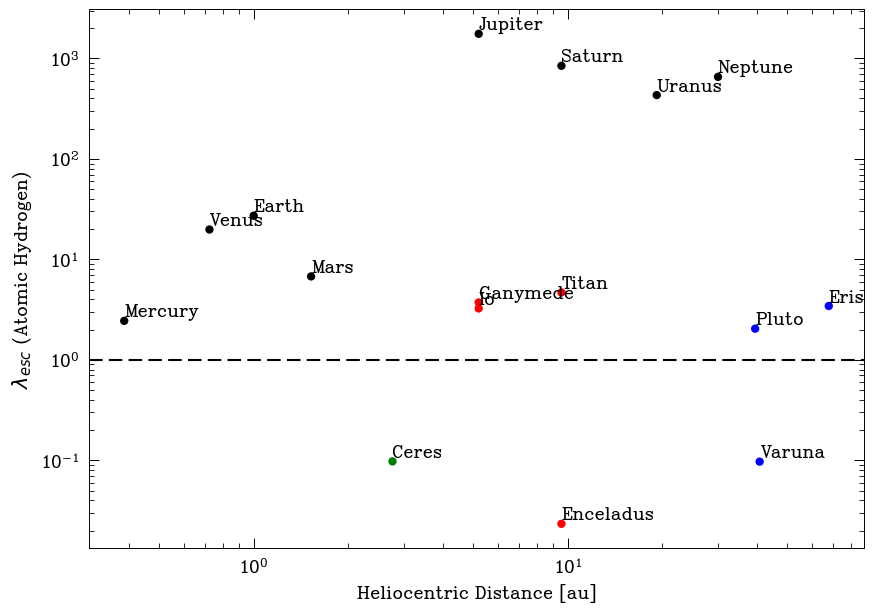

In [65]:
fig, ax = plt.subplots(figsize=(10,7))

ax.axhline(y=1,linestyle='dashed')

for key in planet_dict.keys():
    print(key, lambda_esc(*planet_dict[key][0]))
    ax.scatter(planet_dict[key][0][0],
               lambda_esc(*planet_dict[key][0]),
               c=planet_dict[key][1],
               edgecolor='none')
    ax.text(s=key,x=planet_dict[key][0][0],y=1.1*lambda_esc(*planet_dict[key][0]))

ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel(r"$\lambda_{esc}$ (Atomic Hydrogen)")
ax.set_xlabel("Heliocentric Distance [au]")

## From this we can estimate that bodies with $\lambda_{esc}$ have the potential to hold onto an atmosphere. The gas giants likely experience very little thermal atmospheric escape. The terrestrials have smaller escape parameters, and very little hydrogen. We can assume that in this regime, atmospheres are lost but over longer timescales. Small bodies, like Ceres and Varuna, would have any hydrogen-dominated atmosphere escape nearly instantly.